<a href="https://colab.research.google.com/github/tphan356/household-object-classification/blob/main/code/household_object_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Household Object Classification

A deep learning project focused on classifying common household objects using computer vision, with potential applications in intelligent home robotics.

## Set up

In [1]:
!pip install -q kagglehub

### Import library

In [2]:
import fastai
import kagglehub
import numpy as np
import pandas as pd
import torch
import hashlib

from collections import defaultdict
from pathlib import Path
from fastai.vision.all import *
from fastcore.all import *
from fastdownload import download_url

### Check instrallation

In [3]:
print("Fastai version:", fastai.__version__)
print("PyTorch version:", torch.__version__)
print("GPU available", torch.cuda.is_available())

Fastai version: 2.8.12
PyTorch version: 2.11.0+cu130
GPU available True


## Domain Problem

Recognizing household objects is an important capability for intelligent home robots, such as robot vacuum cleaners. These robots need to identify objects in their environment to better understand their surroundings and support navigation.

The goal of this project is to develop an image classification model that can recognize five common household objects: bed, chair, sofa, swivel chair, and table.

## Analytic Approach

I will take a predictive approach in this project by training an image classifier to recognize five furniture categories: bed, chair, sofa, swivel chair, and table.

The model will learn visual features from labeled images and use them to predict the categories of new, unseen images.

## Household Object Classifier

The dataset comes from [Furniture Detector on Kaggle](https://www.kaggle.com/datasets/akkithetechie/furniture-detector).

The dataset contains five furniture categories:

1. Bed
2. Chair
3. Sofa
4. Swivel Chair
5. Table

I will use these labeled images to train a multiclass image classification model. Before training, I will examine the data, check for duplicates, and split the images into training and validation sets.

### Download the dataset

In [4]:
path = Path(kagglehub.dataset_download("akkithetechie/furniture-detector"))

print("Dataset location:", path)

Using Colab cache for faster access to the 'furniture-detector' dataset.
Dataset location: /kaggle/input/furniture-detector


### Examine the downloaded files

In [5]:
for item in sorted(path.iterdir()):
    print(item.name)

furniture-images
img


### Get all image files

In [6]:
image_root = path / "furniture-images"

if not image_root.exists():
    image_root = path

file_names = get_image_files(image_root)

print("Total image files:", len(file_names))
print("Sample image paths:")

for file in file_names[:5]:
    print(file.relative_to(path))

Total image files: 4447
Sample image paths:
furniture-images/img/val/sofa/00000233.jpg
furniture-images/img/val/sofa/00000277.jpg
furniture-images/img/val/sofa/00000253.jpg
furniture-images/img/val/sofa/00000211.jpg
furniture-images/img/val/sofa/00000267.jpg


### Define the labeling function

In [7]:
class_names = {"bed", "chair", "sofa", "swivelchair", "table"}

def label_function(file_name):
    for folder in Path(file_name).parents:
        name = ''.join(c for c in folder.name.lower() if c.isalpha())

        if name in class_names:
            return name

    raise ValueError(f"No category found for {file_name}")

In [8]:
labeled_files = []

for file in file_names:
    try:
        label_function(file)
        labeled_files.append(file)
    except ValueError:
        pass

class_counts = Counter(label_function(f) for f in labeled_files)

for category, count in sorted(class_counts.items()):
    print(f"{category}: {count} images")

print("Total labeled images:", len(labeled_files))
print("Unlabeled images skipped:", len(file_names) - len(labeled_files))

assert set(class_counts) == class_names, "Check the dataset folder structure."

bed: 1000 images
chair: 1000 images
sofa: 1000 images
swivelchair: 1000 images
table: 447 images
Total labeled images: 4447
Unlabeled images skipped: 0


### Remove dublicated image

In [9]:
def image_hash(file):
    with open(file, 'rb') as f:
        return hashlib.sha256(f.read()).hexdigest()

hash_groups = defaultdict(list)

for file in file_names:
    hash_groups[image_hash(file)].append(file)

unique_files = [
    files[0] for files in hash_groups.values()
    if len({label_function(f) for f in files}) == 1
]

print("Original images:", len(file_names))
print("Clean images:", len(unique_files))

Original images: 4447
Clean images: 4444


The dataset initially contained 4,447 images across five furniture categories. After removing exact duplicates and images with conflicting labels, I obtained **4,444 images**. The dataset is somewhat imbalanced, with fewer table images than the other categories.

### Display multiple sample images

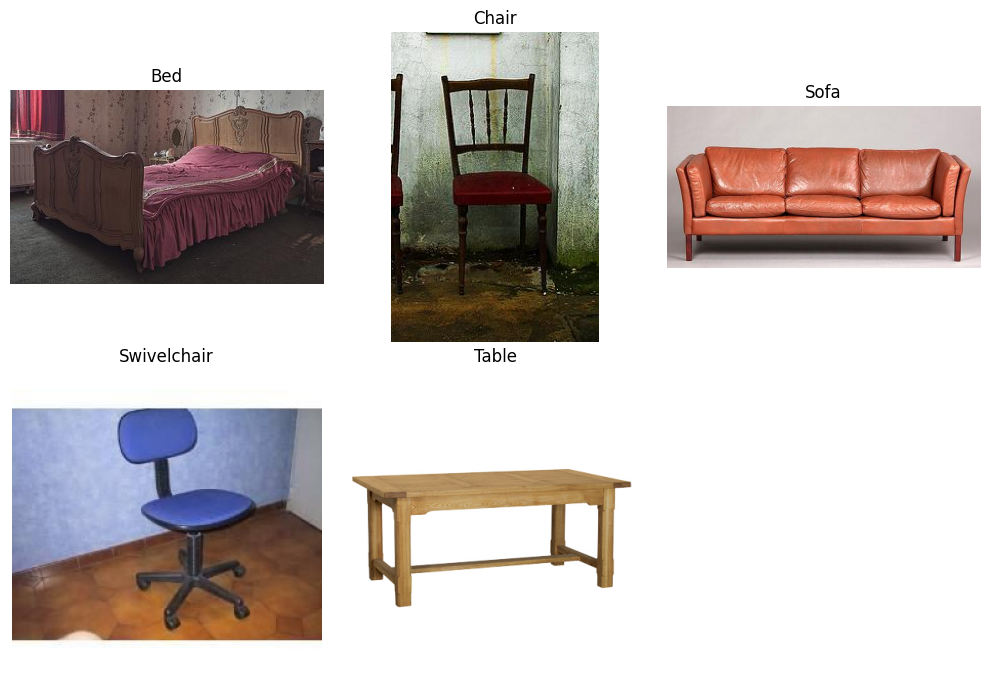

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for ax, category in zip(axes.flat, sorted(class_names)):
    images = [f for f in labeled_files if label_function(f) == category]

    sample = random.choice(images)

    ax.imshow(PILImage.create(sample))
    ax.set_title(category.capitalize())
    ax.axis('off')

for ax in axes.flat[5:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

## Data Processing

The images are organized into five furniture categories, so I can use the folder names as image labels.

Processing of the images (input) and their labels (output) will be done as I set up the neural network model. Since the neural network requires a consistent input image size, I will resize the images before training.

I will first resize images to 460 × 460 pixels, then apply data augmentation to produce 224 × 224 images.

## Set up DataBlock

In [11]:
dblock = DataBlock(
    blocks = (ImageBlock, CategoryBlock),
    get_items = lambda p: unique_files,
    get_y = label_function,
    splitter = RandomSplitter(seed=42),                       # Split images into 80% training and 20% validation
    item_tfms = Resize(460),                                  # Resize each imgage to 460x460 before batching
    batch_tfms = aug_transforms(size = 224, min_scale = 0.75) # Apply data augmentation and resize images to 224x224
)

### Load the data

In [12]:
dls = dblock.dataloaders(image_root)

## Exploratory data analysis

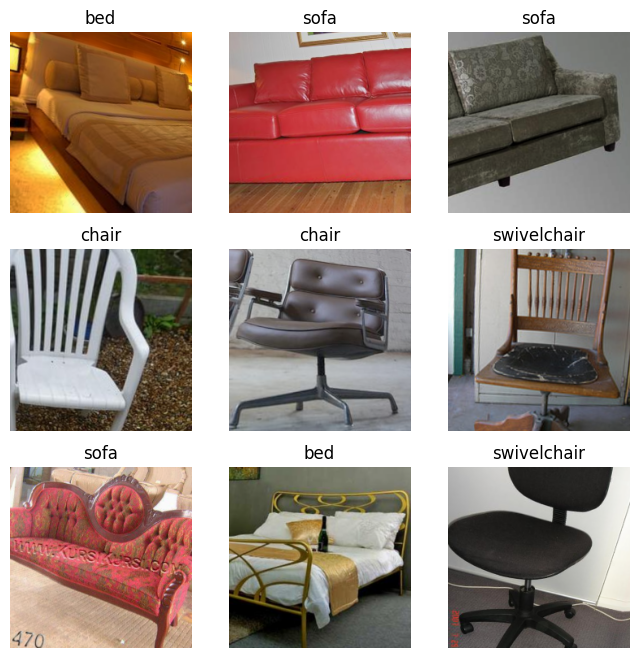

In [13]:
dls.show_batch(max_n = 9, figsize=(8,8))

### Verify dataset

In [14]:
print("Categories:", dls.vocab)
print("Training images:", len(dls.train_ds))
print("Validation images:", len(dls.valid_ds))

Categories: ['bed', 'chair', 'sofa', 'swivelchair', 'table']
Training images: 3556
Validation images: 888


## Modeling — Fine-Tuning

I will use a pretrained ResNet34 neural network to classify five furniture categories. Rather than training a model from scratch, I will use transfer learning to adapt the visual features learned from ImageNet to my dataset.

I will fine-tune the model using Fastai and evaluate its performance on the validation dataset.

### Create the neural network

In [15]:
learn = vision_learner(dls, resnet34, metrics = error_rate)

### Fine-tune the model

In [16]:
learn.fine_tune(1)

epoch,train_loss,valid_loss,error_rate,time
0,0.772598,0.162521,0.055180,00:38


epoch,train_loss,valid_loss,error_rate,time
0,0.227070,0.092973,0.027027,00:38


In [17]:
valid_loss, error = learn.validate()

accuracy = 1 - error

print(f"Validation Accuracy: {accuracy:.2%}")
print(f"Validation Error Rate: {error:.2%}")

Validation Accuracy: 97.30%
Validation Error Rate: 2.70%


### Model Performance

The ResNet34 model achieved **97.30% validation accuracy**, with an error rate of **2.70%** after fine-tuning. The training loss decreased from 0.772598 to 0.227070, while the validation loss decreased from 0.162521 to 0.092973.

These results suggest that the model performs well on the validation dataset, with both training and validation losses decreasing after fine-tuning.

## Model Evaluation

I will use a confusion matrix to evaluate the model's classification performance across the five household object categories. The confusion matrix shows how many images were correctly classified and which categories were confused with one another.

In [18]:
interp = ClassificationInterpretation.from_learner(learn)

Plot the confusion matrix, which shows the number of images in the validation set that were correctly and incorrectly classified by the model.

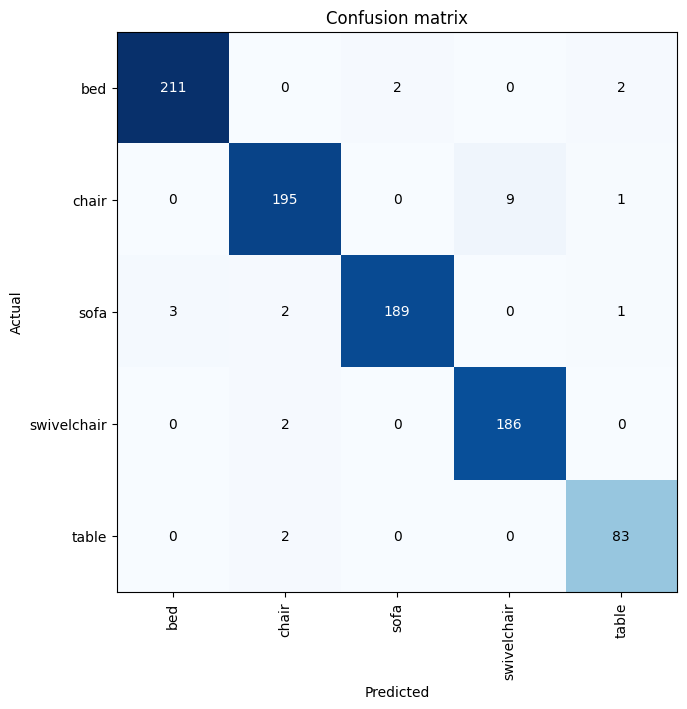

In [19]:
interp.plot_confusion_matrix(figsize=(7, 7))

In [20]:
cm = interp.confusion_matrix()

print(f"Error rate: {(cm.sum() - cm.trace()) / cm.sum():.2%}")

Error rate: 2.70%


### Confusion Matrix Interpretation

The ResNet34 model correctly classified **864 out of 888 validation images**, achieving **97.30% accuracy** and a **2.70% error rate**. The most common misclassification occurred between chairs and swivel chairs, which share similar visual features. Overall, the model performed well across all five furniture categories.

### Identify the most confused categories

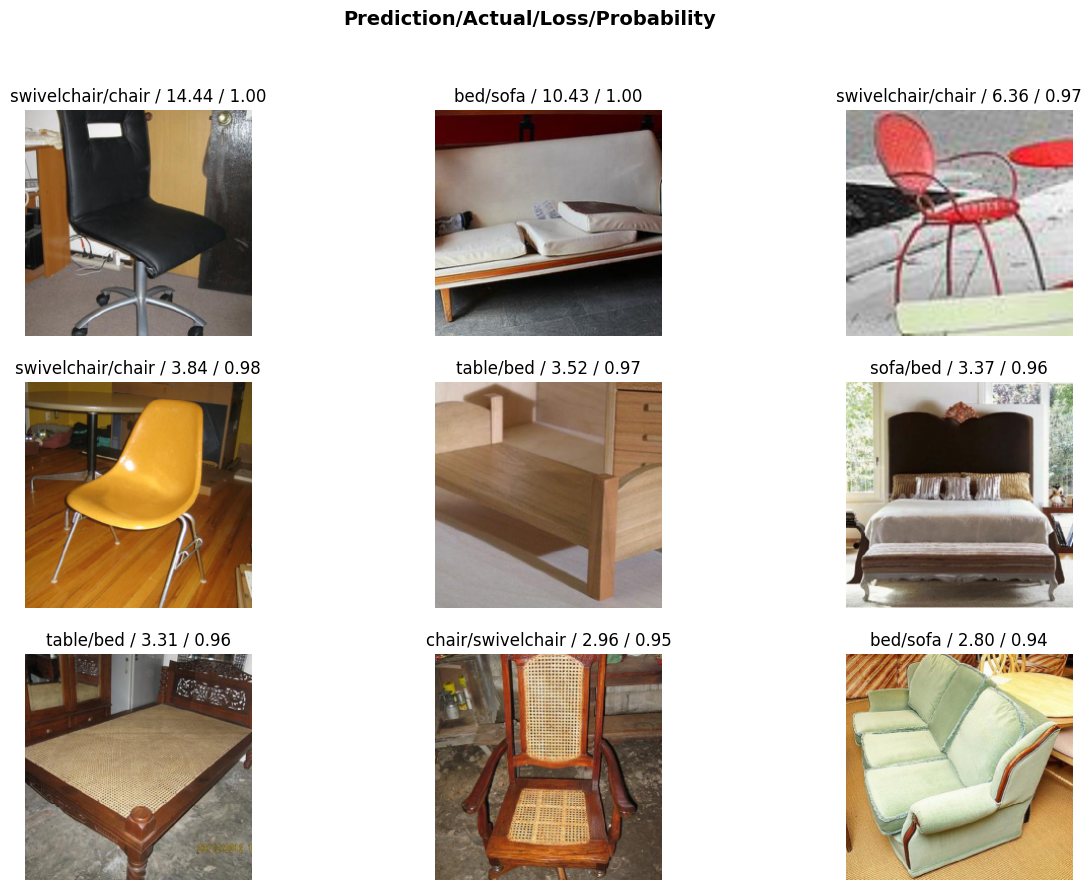

In [21]:
interp.plot_top_losses(9, figsize=(15, 10))

### Error Analysis

The highest-loss images show that the model sometimes struggles to distinguish furniture with similar shapes, particularly chairs and swivel chairs. Some unusual furniture designs and viewing angles also contribute to incorrect predictions.

## Prediction on an External Image

To evaluate how well the model generalizes beyond the Kaggle dataset, I will test it on a new image downloaded from the internet.

I selected a chair photograph from [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Chair_2020_P01.jpg), photographed by Fallaner (CC BY-SA 4.0).

I will use the trained ResNet34 model to predict the furniture category and examine its confidence score.

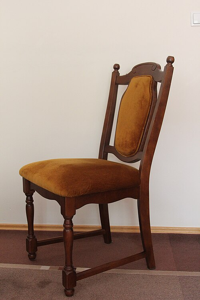

Actual category: chair
Predicted category: chair
Confidence: 100.00%


In [27]:
external_url = "https://thumb.wikimedia.org/wikipedia/commons/thumb/0/04/Chair_2020_P01.jpg/500px-Chair_2020_P01.jpg"

external_image_path = Path("external_chair.jpg")

download_url(external_url, external_image_path, show_progress=False)

img = PILImage.create(external_image_path)
display(img.to_thumb(300))

prediction, pred_idx, probabilities = learn.predict(img)

print("Actual category: chair")
print("Predicted category:", prediction)
print(f"Confidence: {probabilities[pred_idx]:.2%}")

### External Image Prediction

I tested the ResNet34 model on a chair image downloaded from Wikimedia Commons, which was not included in the Kaggle dataset. The model correctly classified the image as a **chair with 100.00% confidence**.

This result suggests that the model can recognize furniture in unseen images, although additional external testing is needed to evaluate its generalization.

## Conclusion

I used transfer learning with a pretrained ResNet34 model to classify five furniture categories. The model achieved **97.30% validation accuracy** and a **2.70% error rate**. The main challenge was distinguishing visually similar furniture, particularly chairs and swivel chairs.

In the future, I would like to extend this project to object detection and semantic mapping for intelligent home robots.